# Sujet 3 — Notebook 3 : évaluation

**Jeu de test** : 20 ordonnances construites à la main (`donnees/ordonnances.json`), dont 3 sans interaction attendue, 1 polymédication de 8 médicaments, 1 avec un médicament absent du graphe. **Vérité terrain** : 26 paires à risque avec leur niveau, établies d'après le Thésaurus ANSM et des RCP (`donnees/verite_terrain.csv`).

**Référence non hybride** : recherche exacte de la paire dans une liste de 24 interactions prototypes (`donnees/liste_paires_reference.csv`).

Dimensions de la grille couvertes : **performance** (précision, rappel, F1), **cohérence** (niveau de gravité correct), **explicabilité** (chemin + règle + source pour chaque alerte), **robustesse** (saisie, généralisation), **calibration** (bonus ProbLog, notebook 4), **coût** (alertes par ordonnance, temps).

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Les modules sont dans src/. Sur Colab : importez sujet3_projet.zip puis exécutez
# !unzip -q sujet3_projet.zip   (le dossier projet/ apparaît à côté du notebook)
ICI = Path.cwd()
for c in [ICI, ICI / "src", ICI.parent / "src", ICI / "projet" / "src"]:
    if (c / "graphe.py").exists():
        sys.path.insert(0, str(c)); break

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

import matplotlib.pyplot as plt
from graphe import charger_graphe
from regles import Verificateur
from evaluation import (charger_verite, evaluer, systeme_hybride, systeme_liste_paires,
                        ablation, par_famille, analyser_erreurs, robustesse, generalisation)

G = charger_graphe()
_, verite = charger_verite()
print(len(verite), "paires attendues ;", verite.niveau.value_counts().sort_index().to_dict())

26 paires attendues ; {1: 6, 2: 8, 3: 9, 4: 3}


## 1. Résultat principal : hybride contre référence

In [2]:
hyb, det_hyb = evaluer(systeme_hybride(Verificateur(G)))
ref, det_ref = evaluer(systeme_liste_paires(Verificateur(G)))
display(pd.DataFrame({"Hybride (graphe + règles)": hyb, "Référence : liste de paires": ref}).T)

,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
Hybride (graphe + règles),20.0,2.0,6.0,0.909,0.769,0.833,1.10,0.95,0.95,0.85
Référence : liste de paires,11.0,0.0,15.0,1.000,0.423,0.595,0.55,1.00,1.00,0.01


## 2. Ablation : retirer une brique à la fois

In [3]:
abl = ablation(G)
display(abl)

,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
configuration,,,,,,,,,,
Hybride complet (concis),20,2,6,0.909,0.769,0.833,1.10,0.950,0.950,0.87
Hybride sans filtre anti-fatigue,24,45,2,0.348,0.923,0.505,3.45,0.875,0.917,1.41
– sans filtre « marge étroite » sur G1,20,10,6,0.667,0.769,0.714,1.50,0.950,0.950,0.79
+ corroboration G2+G3 (option),21,11,5,0.656,0.808,0.724,1.60,0.905,0.905,0.77
– sans règles expertes (graphe seul),5,1,21,0.833,0.192,0.312,0.30,0.800,0.800,0.34
– sans règle pharmacocinétique G1,16,1,10,0.941,0.615,0.744,0.85,1.000,1.000,0.72
– sans règles génériques G1-G3,16,1,10,0.941,0.615,0.744,0.85,1.000,1.000,0.42
– sans table ATC (classes du graphe seules),7,1,19,0.875,0.269,0.412,0.40,0.857,0.857,0.73
– sans classes du graphe (table seule),20,1,6,0.952,0.769,0.851,1.05,0.950,0.950,0.52


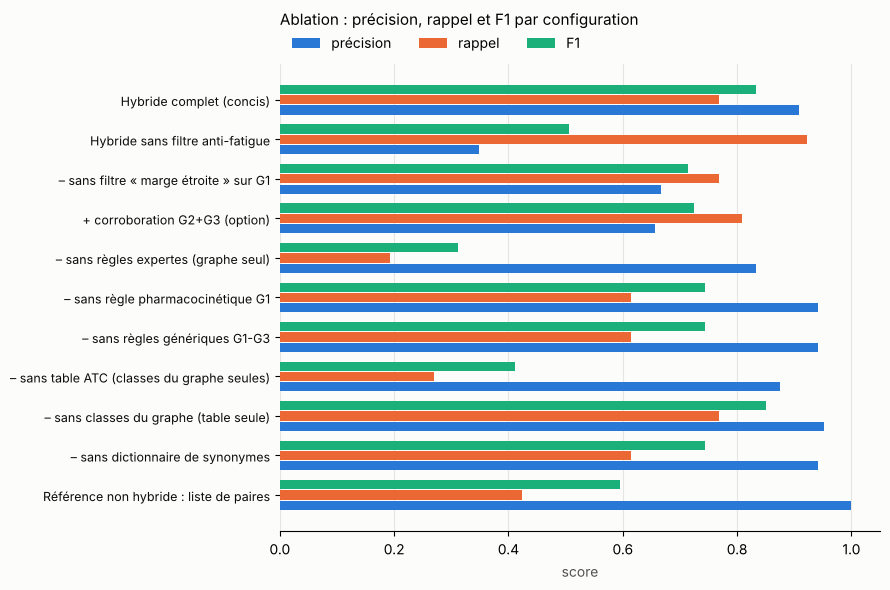

In [4]:
cfg = abl.index.tolist()[::-1]
y = range(len(cfg)); h = 0.26
couleurs = {"précision": "#2a78d6", "rappel": "#eb6834", "F1": "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for k, (m, c) in enumerate(couleurs.items()):
    ax.barh([i + (k - 1) * h for i in y], abl.loc[cfg, m], height=h * 0.9, color=c, label=m)
ax.set_yticks(list(y)); ax.set_yticklabels(cfg, fontsize=9, color="#0b0b0b")
ax.set_xlim(0, 1.05); ax.set_xlabel("score", color="#52514e")
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
ax.set_title("Ablation : précision, rappel et F1 par configuration", loc="left", fontsize=11, pad=28)
plt.tight_layout(); plt.show()

**Lecture de l'ablation.**

- **Règles expertes** : c'est la brique principale. Sans elles (graphe seul), le rappel tombe de 0,77 à 0,19.
- **Règle pharmacocinétique G1** : elle ajoute 4 vraies alertes qu'aucune règle experte ne couvre (warfarine + fluconazole, warfarine + amiodarone, colchicine + clarithromycine, glibenclamide + fluconazole), au prix d'un faux positif.
- **Filtre « marge étroite »** : sans lui, G1 produit 8 faux positifs de plus. C'est la combinaison **graphe (mécanisme) + connaissance clinique (quel médicament est dangereux à surdoser)** qui rend la règle utile.
- **Filtre anti-fatigue** : sans lui, le rappel monte à 0,92 mais avec 3,45 alertes par ordonnance et une précision de 0,35 — inutilisable en pratique.
- **Table ATC** : sans elle, le rappel s'effondre (0,27) : le graphe ne classe ni les statines, ni les IEC, ni les IPDE5, ni les ISRS courants.
- **Classes du graphe** : les retirer *améliore* légèrement le résultat sur ce jeu (le faux positif aspirine-AINS disparaît). Ce n'est pas une preuve d'inutilité : la table a été écrite pour les médicaments du jeu de test. Le test de généralisation (section 5) montre l'inverse.

## 3. Contribution de chaque famille de règles, seule

In [5]:
display(par_famille(G))

,famille seule,mode,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
0,classe,concis,16,1,10,0.941,0.615,0.744,0.85,1.000,1.000,0.79
1,classe,complet,16,1,10,0.941,0.615,0.744,0.85,1.000,1.000,0.95
2,pk,concis,5,1,21,0.833,0.192,0.312,0.30,0.800,0.800,0.08
3,pk,complet,7,9,19,0.438,0.269,0.333,0.80,0.571,0.571,0.15
4,effet,concis,0,0,26,0.000,0.000,0.000,0.00,NaN,NaN,0.54
5,effet,complet,19,43,7,0.306,0.731,0.432,3.10,0.316,0.474,0.42
6,cible,concis,0,0,26,0.000,0.000,0.000,0.00,NaN,NaN,0.06
7,cible,complet,2,2,24,0.500,0.077,0.133,0.20,0.500,0.500,0.07


## 4. Analyse d'erreurs : chaque erreur attribuée à sa brique

In [6]:
err = analyser_erreurs(G)
display(err)
display(err["brique responsable"].str.split(" :| \\(").str[0].value_counts().to_frame("erreurs"))

,ordonnance,paire,erreur,niveau attendu,niveau prédit,brique responsable
0,O01,Omeprazole + Warfarin,FP,NaN,2.0,Règle générique du graphe trop large (G1)
1,O02,Amlodipine + Simvastatin,FN,2.0,NaN,"Règle manquante : aucune règle experte, rien dans le graphe"
2,O05,Furosemide + Lisinopril,FN,2.0,NaN,"Filtre anti-fatigue : seulement G2 (niveau 1, masqué)"
3,O06,Ketoprofen + Prednisone,FN,1.0,NaN,"Filtre anti-fatigue : seulement G2 (niveau 1, masqué)"
4,O07,Digoxin + Furosemide,FN,2.0,NaN,"Règle manquante : aucune règle experte, rien dans le graphe"
5,O14,Allopurinol + Azathioprine,FN,3.0,NaN,"Filtre anti-fatigue : seulement G2, G3 (niveau 1, masqué)"
6,O18,Acetylsalicylic acid + Ramipril,FP,NaN,2.0,Classe du graphe trop large (R16)
7,O20,Ibuprofen + Sertraline,FN,1.0,NaN,"Filtre anti-fatigue : seulement G2 (niveau 1, masqué)"


,erreurs
brique responsable,
Filtre anti-fatigue,4
Règle manquante,2
Règle générique du graphe trop large,1
Classe du graphe trop large,1


**Lecture.**

| Brique | Erreurs | Explication |
|---|---|---|
| Filtre anti-fatigue | 4 FN | Les seuls signaux étaient des effets partagés (G2) ou une cible commune (G3), masqués car trop fréquents. Allopurinol + azathioprine est un vrai cas où le graphe *savait* (cible commune XDH) mais où le signal était noyé. |
| Règle manquante | 2 FN | Digoxine + furosémide (hypokaliémie) et simvastatine + amlodipine : aucune règle écrite, rien d'exploitable dans le graphe. |
| Graphe (classe trop large) | 1 FP | Aspirine classée AINS dans Hetionet ; à dose antiagrégante, l'interaction AINS + IEC ne s'applique pas. Le graphe n'a pas de notion de dose. |
| Graphe (règle G1) | 1 FP | Oméprazole + warfarine : l'oméprazole est un inhibiteur faible du CYP2C19, mais le graphe ne code pas la **force** de l'inhibition. |

## 5. Cas difficiles : généralisation à des médicaments absents de la table

In [7]:
display(generalisation(G))

,VP,FP,FN,précision,rappel,F1,alertes / ordonnance,niveau exact (VP),niveau ±1 (VP),ms / ordonnance
configuration,,,,,,,,,,
Hybride (graphe + table),5,0,0,1.0,1.0,1.000,1.0,1.0,1.0,0.63
Table ATC seule,0,0,5,0.0,0.0,0.000,0.0,NaN,NaN,0.37
Classes du graphe seules,2,0,3,1.0,0.4,0.571,0.4,1.0,1.0,0.33
Référence : liste de paires,0,0,5,0.0,0.0,0.000,0.0,NaN,NaN,0.01


**Lecture.** Sur 5 ordonnances dont l'AINS ou l'antiagrégant n'est **pas** dans la table du groupe (célécoxib, méloxicam, indométacine, piroxicam, ticlopidine), la table seule et la liste de paires ne trouvent rien ; le graphe classe ces médicaments (PCiC) et la règle experte s'applique. Inversement, les classes du graphe seules ne trouvent que 2 alertes sur 5, car le graphe ne classe ni le rivaroxaban, ni le lithium, ni le méthotrexate dans une classe utile.

**Les deux sources de connaissance sont complémentaires** : c'est l'argument central de l'approche hybride.

## 6. Robustesse : variantes de saisie des noms

In [8]:
display(robustesse(G))

,variante de saisie,reconnaissance,non reconnus,reconnus « à confirmer »,rappel,précision
0,saisie d'origine,synonymes + approché,0,0,0.769,0.909
1,saisie d'origine,synonymes seuls,0,0,0.769,0.909
2,saisie d'origine,aucun (noms du graphe),29,0,0.269,1.000
3,MAJUSCULES,synonymes + approché,0,0,0.769,0.909
4,MAJUSCULES,synonymes seuls,0,0,0.769,0.909
5,MAJUSCULES,aucun (noms du graphe),29,0,0.269,1.000
6,sans accents,synonymes + approché,0,0,0.769,0.909
7,sans accents,synonymes seuls,0,0,0.769,0.909
8,sans accents,aucun (noms du graphe),26,0,0.269,1.000
9,faute de frappe (lettre doublée),synonymes + approché,0,62,0.769,0.909


**Lecture.** Sans dictionnaire de synonymes, 29 noms sur 62 ne sont pas reconnus (DCI françaises, noms commerciaux) et le rappel chute à 0,27. Avec une lettre doublée dans chaque nom, seule la correspondance approchée sauve le rappel ; chaque nom reconnu ainsi est **signalé « à confirmer »** au prescripteur.

## 7. Coût

- **Alertes par ordonnance** : 1,10 en mode concis contre 3,45 en mode complet (en mode complet, les 24 vraies alertes trouvées sont noyées parmi 69).
- **Temps** : moins de 1 ms par ordonnance une fois le graphe chargé (chargement initial : environ 2 s).

## 8. Explicabilité

100 % des alertes portent la règle, sa source et le chemin dans le graphe ou la ligne de table (voir notebook 2). Une alerte sans justification ne peut pas être produite par construction.

In [9]:
from reference_llm import ollama_disponible, systeme_llm
if ollama_disponible():
    res_llm, _ = evaluer(systeme_llm(Verificateur(G), modele="llama3.2:3b"))
    display(pd.DataFrame({"LLM sans graphe": res_llm}).T)
else:
    print("Ollama n'est pas lancé : deuxième référence (LLM sans graphe) non évaluée.")
    print("Pour l'activer : installer Ollama, `ollama pull llama3.2:3b`, puis relancer cette cellule.")

Ollama n'est pas lancé : deuxième référence (LLM sans graphe) non évaluée.
Pour l'activer : installer Ollama, `ollama pull llama3.2:3b`, puis relancer cette cellule.
